# ANÁLISE DA PRECIPITAÇÃO NA UGRH PARANAPANEMA

A Unidade de Gestão de Recursos Hídricos (UGRH) Paranapanema localiza-se na divisa entre os estados de São Paulo e Paraná, sendo de vital importância para a geração hidrelétrica e agropecuária. Este estudo avalia os impactos das mudanças climáticas globais sobre o regime pluviométrico da bacia utilizando simulações de um ensemble de 40 membros de um modelo climático global (geração CMIP5), nos períodos HIST (1850–1919), 20C (1920–2005) e RCP8.5 (2006–2100). Os três conjuntos são **saídas de modelo**, não observações.

*Trabalho Integrador da disciplina de Mudanças Climáticas — UFF (Prof. André Belém).*

# Etapa 1: Importação, Limpeza de Calendário e Resampling Temporal

Esta etapa tem como objetivo realizar o tratamento inicial das séries temporais de precipitação diária dos cenários HIST, 20C e RCP8.5 da UGRH Paranapanema. O foco é isolar o sinal de baixa frequência, removendo os ruídos diários.

Para isso, o fluxo de trabalho consiste em:
1. Carregar as séries temporais convertendo a coluna de tempo em um `DatetimeIndex` do Pandas.
2. Filtrar e remover os dias **29 de fevereiro** para padronizar os calendários dos modelos climáticos globais.
3. Agrupar os dados diários em **acumulados mensais** utilizando a função `.resample('ME').sum()`.

### Critério de Seleção de Membro por Correlação Climatológica Sazonal

Em modelos climáticos globais (GCMs), as simulações do século XX (`20C`) e do cenário futuro (`RCP8.5`) são geradas de forma estocástica e livre a partir de condições radiativas de contorno. Isso implica que essas projeções **não possuem correspondência cronológica linear ou síncrona ano a ano (ou mês a mês)** com as séries históricas reais observadas (`HIST`). Uma análise de correlação ponto a ponto direta no tempo produziria coeficientes espúrios ou nulos, ignorando o desempenho real do modelo.

Para contornar essa barreira conceitual e garantir uma seleção metodológica robusta para a **UGRH Paranapanema**, adotou-se o critério da **Correlação Climatológica Sazonal**:

1. Reduziu-se a série temporal de referência histórica (`HIST`) ao seu vetor de perfil sazonal médio de 12 meses (janeiro a dezembro), estabelecendo o comportamento físico esperado do regime hidrológico da bacia.
2. Comprimiu-se cada um dos 40 membros dos conjuntos simulados (`20C` e `RCP8.5`) em suas respectivas curvas de climatologia de 12 meses.
3. Calculou-se o Coeficiente de Correlação de Pearson ($r$) comparando os vetores sazonais de cada membro simulado contra a referência HIST.

O membro que demonstrou a maior correlação positiva durante o período presente (`20C`) foi selecionado como o nosso balizador climático (destacado em **vermelho** nos gráficos gerados). Esse mesmo membro foi automaticamente selecionado na projeção futura `RCP8.5`, preservando a coerência interna da resposta termodinâmica daquele modelo de clima global.

In [1]:
!pip install pyarrow

Mounted at /content/drive
🔍 Calculando perfis sazonais e matrizes de correlação climatológica...

🏆 Membro Escolhido por Assinatura Sazonal: member_103
   -> Correlação do ciclo de chuvas no Presente (20C): 0.9993
   -> Correlação do ciclo de chuvas no Futuro (RCP8.5): 0.9962


/tmp/ipykernel_3668/3426105774.py:91: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(df_corr_20c['member'], rotation=90, fontsize=9)
/tmp/ipykernel_3668/3426105774.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df_corr_rcp['member'], rotation=90, fontsize=9)


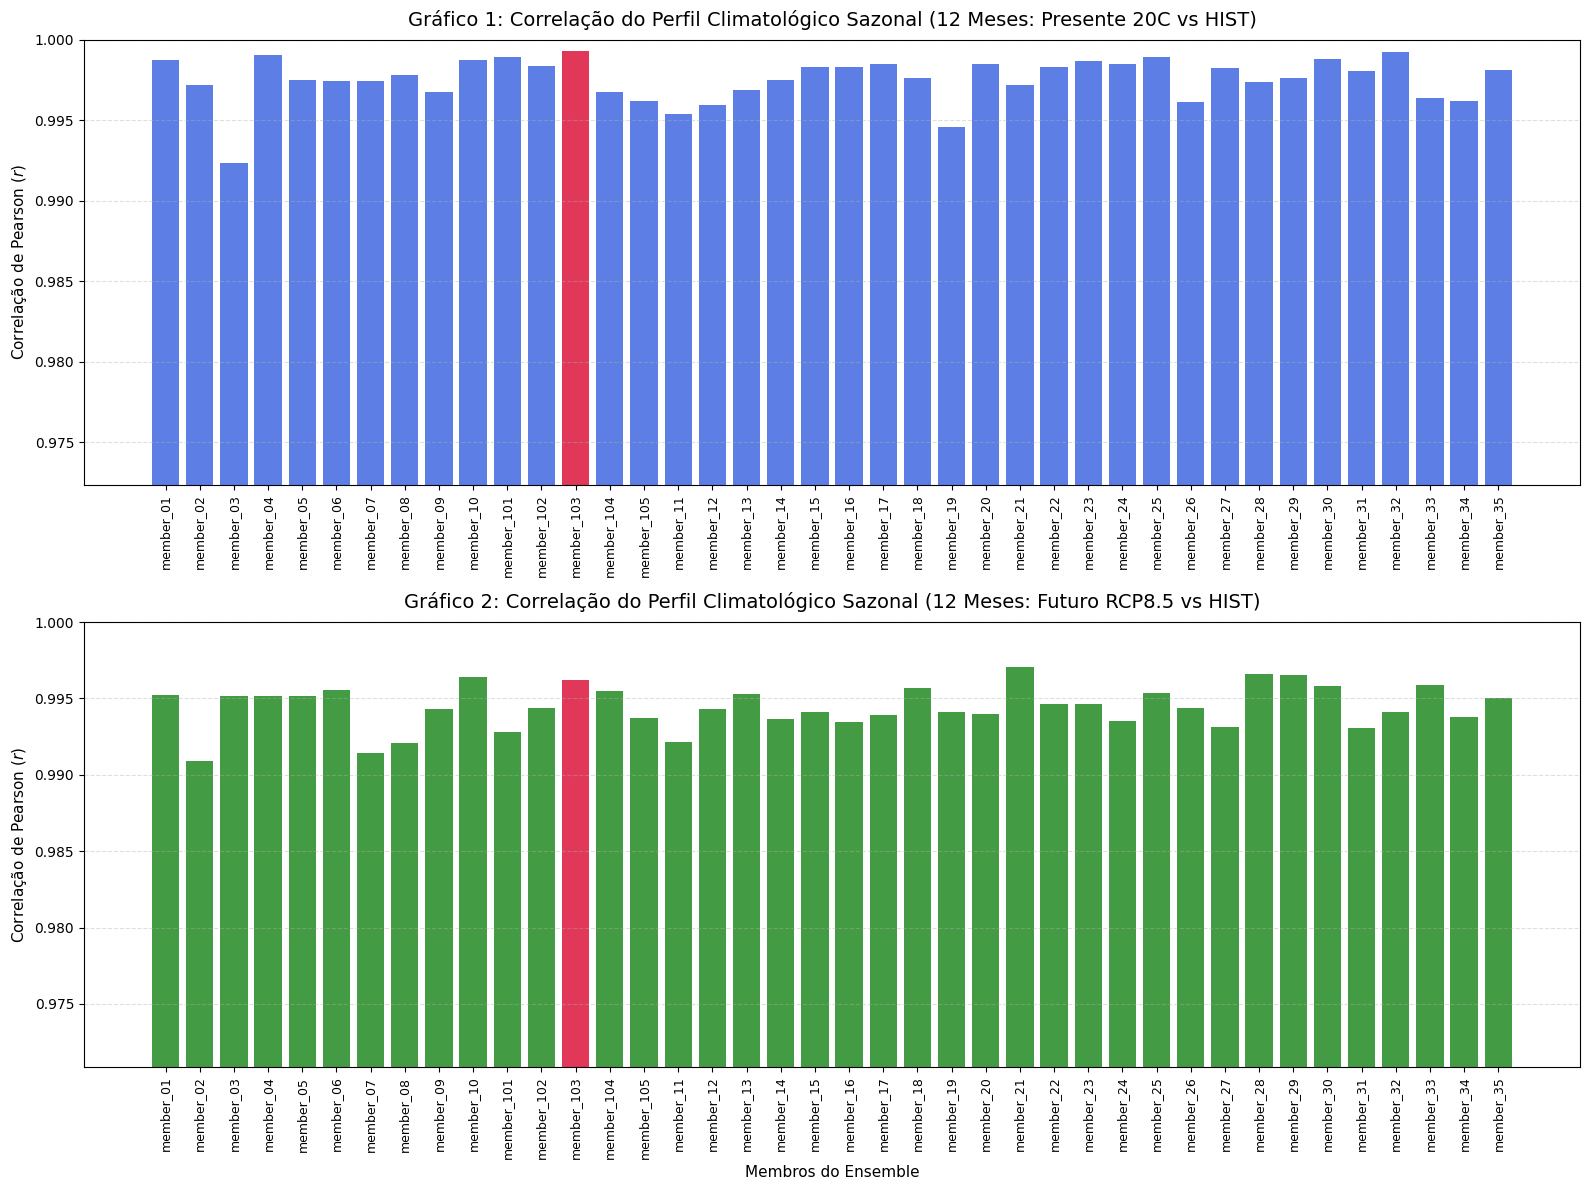


--- SELEÇÃO DO MEMBRO CONCLUÍDA ---
--- ETAPA 1 CONCLUÍDA ---
HIST Mensal: 1850 a 1919 | Total de meses: 840
20C Mensal:  1920 a 2005 | Total de meses: 1032
RCP8.5 Mensal: 2006 a 2100 | Total de meses: 1140


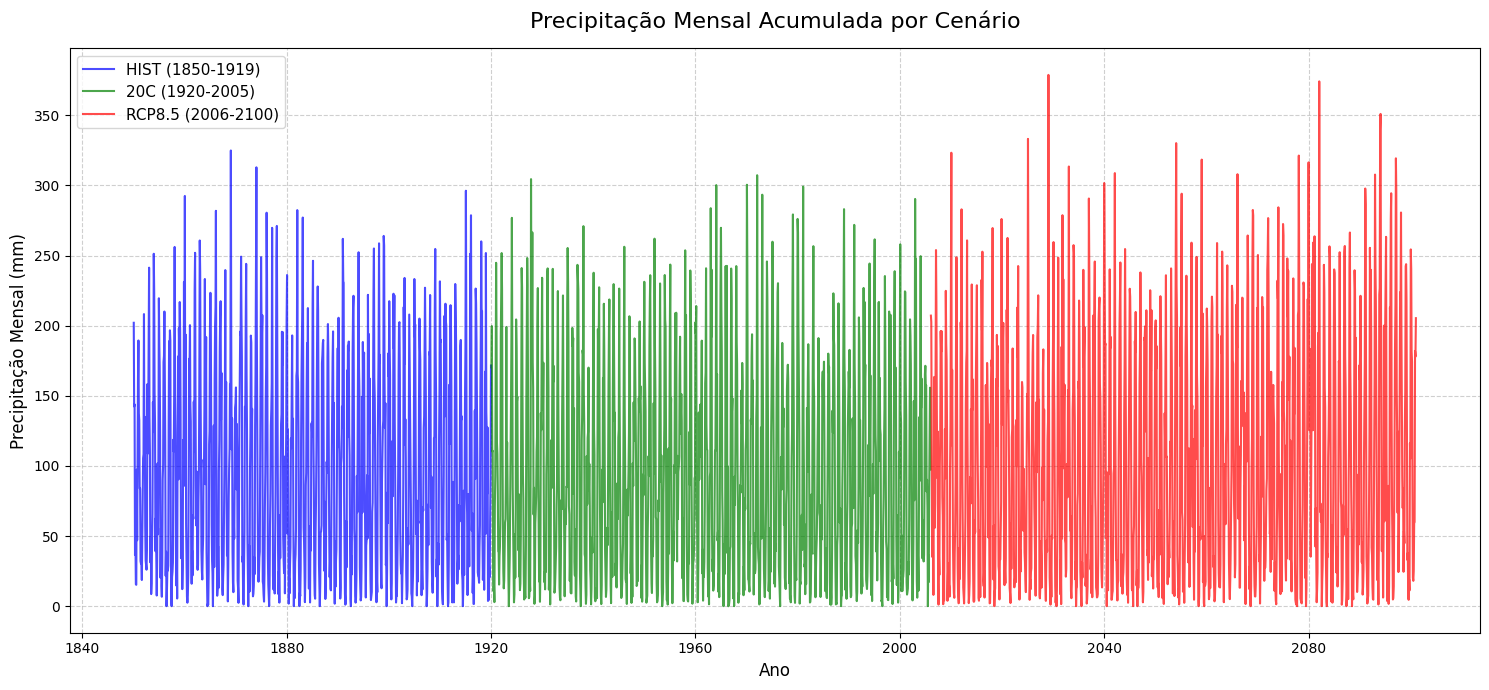

In [2]:
import pandas as pd
import numpy as np
import os
from google.colab import drive
import matplotlib.pyplot as plt

drive.mount('/content/drive')

# 1. Definição dos caminhos dos arquivos .parquet no Google Drive
path = '/content/drive/MyDrive/Mudanças Climáticas/'
arq_hist = os.path.join(path, 'paranapanema-hist.parquet')
arq_20c  = os.path.join(path, 'paranapanema-20c.parquet')
arq_rcp85 = os.path.join(path, 'paranapanema-rcp85.parquet')

# 2. Carregamento dos dados usando a engine pyarrow
df_hist = pd.read_parquet(arq_hist, engine='pyarrow')
df_20c  = pd.read_parquet(arq_20c, engine='pyarrow')
df_rcp85 = pd.read_parquet(arq_rcp85, engine='pyarrow')

# 3. Configuração do Índice Temporal utilizando a coluna 'time' (índice 1 no HIST, índice 3 no 20C/RCP)
df_hist = df_hist.set_index('time')
df_20c  = df_20c.set_index('time')
df_rcp85 = df_rcp85.set_index('time')

# Garante que o índice seja interpretado como Datetime pelo Pandas
df_hist.index = pd.to_datetime(df_hist.index)
df_20c.index = pd.to_datetime(df_20c.index)
df_rcp85.index = pd.to_datetime(df_rcp85.index)

# 4. Remoção dos dias 29 de fevereiro (anos bissextos) conforme diretriz de aula
df_hist_limpo = df_hist[~((df_hist.index.month == 2) & (df_hist.index.day == 29))]
df_20c_limpo  = df_20c[~((df_20c.index.month == 2) & (df_20c.index.day == 29))]
df_rcp85_limpo = df_rcp85[~((df_rcp85.index.month == 2) & (df_rcp85.index.day == 29))]

# ==============================================================================
# PASSO 1.5: SELEÇÃO DO MEMBRO VIA CORRELAÇÃO CLIMATOLÓGICA SAZONAL (12 MESES)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("🔍 Calculando perfis sazonais e matrizes de correlação climatológica...")

# 1. CLIMATOLOGIA DE REFERÊNCIA (HIST) - Vetor de 12 meses
diario_hist = df_hist_limpo.groupby(level=0)['mean_mm_day'].mean()
precip_mensal_hist = diario_hist.resample('ME').sum()
climatologia_hist = precip_mensal_hist.groupby(precip_mensal_hist.index.month).mean()

membros = df_20c_limpo['member'].unique()
corr_20c_sazonal = []
corr_rcp_sazonal = []

# 2. CÁLCULO DA CORRELAÇÃO DO PERFIL DE 12 MESES PARA CADA MEMBRO
for m in membros:
    # --- Perfil Sazonal do Presente Simulado (20C) ---
    df_m_20c = df_20c_limpo[df_20c_limpo['member'] == m]
    mensal_m_20c = df_m_20c.groupby(df_m_20c.index)['mean_mm_day'].mean().resample('ME').sum()
    climatologia_m_20c = mensal_m_20c.groupby(mensal_m_20c.index.month).mean()

    r_20c = climatologia_hist.corr(climatologia_m_20c)
    corr_20c_sazonal.append({'member': m, 'correlacao': r_20c})

    # --- Perfil Sazonal do Futuro Projetado (RCP8.5) ---
    df_m_rcp = df_rcp85_limpo[df_rcp85_limpo['member'] == m]
    mensal_m_rcp = df_m_rcp.groupby(df_m_rcp.index)['mean_mm_day'].mean().resample('ME').sum()
    climatologia_m_rcp = mensal_m_rcp.groupby(mensal_m_rcp.index.month).mean()

    r_rcp = climatologia_hist.corr(climatologia_m_rcp)
    corr_rcp_sazonal.append({'member': m, 'correlacao': r_rcp})

df_corr_20c = pd.DataFrame(corr_20c_sazonal).sort_values('member')
df_corr_rcp = pd.DataFrame(corr_rcp_sazonal).sort_values('member')

# O critério de escolha do membro campeão será quem teve o melhor desempenho no presente (20C)
membro_campeao = df_corr_20c.loc[df_corr_20c['correlacao'].idxmax()]['member']
corr_campeao_20c = df_corr_20c['correlacao'].max()
corr_campeao_rcp = df_corr_rcp[df_corr_rcp['member'] == membro_campeao]['correlacao'].values[0]

print(f"\n🏆 Membro Escolhido por Assinatura Sazonal: {membro_campeao}")
print(f"   -> Correlação do ciclo de chuvas no Presente (20C): {corr_campeao_20c:.4f}")
print(f"   -> Correlação do ciclo de chuvas no Futuro (RCP8.5): {corr_campeao_rcp:.4f}")

# 3. PLOTAGEM DOS DOIS GRÁFICOS DE BARRAS DE CORRELAÇÃO SAZONAL
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 12))

# Gráfico 1: Sazonalidade 20C vs HIST
cores_20c = ['crimson' if m == membro_campeao else 'royalblue' for m in df_corr_20c['member']]
ax1.bar(df_corr_20c['member'], df_corr_20c['correlacao'], color=cores_20c, alpha=0.85)
ax1.set_title('Gráfico 1: Correlação do Perfil Climatológico Sazonal (12 Meses: Presente 20C vs HIST)', fontsize=14, pad=10)
ax1.set_ylabel('Correlação de Pearson ($r$)', fontsize=11)
ax1.set_xticklabels(df_corr_20c['member'], rotation=90, fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.4, axis='y')
ax1.set_ylim(df_corr_20c['correlacao'].min() - 0.02, 1.0)

# Gráfico 2: Sazonalidade RCP8.5 vs HIST
cores_rcp = ['crimson' if m == membro_campeao else 'forestgreen' for m in df_corr_rcp['member']]
ax2.bar(df_corr_rcp['member'], df_corr_rcp['correlacao'], color=cores_rcp, alpha=0.85)
ax2.set_title('Gráfico 2: Correlação do Perfil Climatológico Sazonal (12 Meses: Futuro RCP8.5 vs HIST)', fontsize=14, pad=10)
ax2.set_xlabel('Membros do Ensemble', fontsize=11)
ax2.set_ylabel('Correlação de Pearson ($r$)', fontsize=11)
ax2.set_xticklabels(df_corr_rcp['member'], rotation=90, fontsize=9)
ax2.grid(True, linestyle='--', alpha=0.4, axis='y')
ax2.set_ylim(df_corr_rcp['correlacao'].min() - 0.02, 1.0)

plt.tight_layout()
plt.show()

# 4. FILTRAGEM E DEFINIÇÃO DAS SÉRIES TEMPORAIS PARA O RESTANTE DO NOTEBOOK
df_20c_champion = df_20c_limpo[df_20c_limpo['member'] == membro_campeao]
diario_20c_filtrado = df_20c_champion.groupby(level=0)['mean_mm_day'].mean()
precip_mensal_20c  = diario_20c_filtrado.resample('ME').sum()

df_rcp85_champion = df_rcp85_limpo[df_rcp85_limpo['member'] == membro_campeao]
diario_rcp85_filtrado = df_rcp85_champion.groupby(level=0)['mean_mm_day'].mean()
precip_mensal_rcp85 = diario_rcp85_filtrado.resample('ME').sum()

print("\n--- SELEÇÃO DO MEMBRO CONCLUÍDA ---")

# 6. Verificação do sucesso do processamento das séries
print("--- ETAPA 1 CONCLUÍDA ---")
print(f"HIST Mensal: {precip_mensal_hist.index.min().year} a {precip_mensal_hist.index.max().year} | Total de meses: {len(precip_mensal_hist)}")
print(f"20C Mensal:  {precip_mensal_20c.index.min().year} a {precip_mensal_20c.index.max().year} | Total de meses: {len(precip_mensal_20c)}")
print(f"RCP8.5 Mensal: {precip_mensal_rcp85.index.min().year} a {precip_mensal_rcp85.index.max().year} | Total de meses: {len(precip_mensal_rcp85)}")

# 7. Geração do gráfico das séries mensais completas
plt.figure(figsize=(15, 7))
plt.plot(precip_mensal_hist.index, precip_mensal_hist, label='HIST (1850-1919)', color='blue', alpha=0.7)
plt.plot(precip_mensal_20c.index, precip_mensal_20c, label='20C (1920-2005)', color='green', alpha=0.7)
plt.plot(precip_mensal_rcp85.index, precip_mensal_rcp85, label='RCP8.5 (2006-2100)', color='red', alpha=0.7)

plt.title('Precipitação Mensal Acumulada por Cenário', fontsize=16, pad=15)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Precipitação Mensal (mm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Etapa 2: Remoção da Sazonalidade e Extração do Sinal de Baixa Frequência

Conforme as diretrizes metodológicas da disciplina, a análise de tendências climáticas em séries longas exige a separação entre o ciclo sazonal anual e as variações estruturais de longo prazo.

Para isolar o sinal de baixa frequência, esta etapa realiza:
1. O cálculo da **Climatologia de Referência** baseada no cenário HIST, extraindo o valor médio esperado para cada um dos 12 meses do ano.
2. O cálculo das **Séries de Anomalias**, subtraindo a climatologia mensal correspondente de cada registro dos cenários HIST, 20C e RCP8.5.
3. A aplicação de um filtro de **Média Móvel de 13 meses** sobre as anomalias, suavizando os ruídos transientes e evidenciando as oscilações interdecenais e quebras de tendência climática na UGRH Paranapanema.

--- ETAPA 2 CONCLUÍDA COM SUCESSO ---
Perfil da Climatologia HIST (Média Mensal Esperada em mm):
 Mês 01: 215.47 mm
 Mês 02: 171.75 mm
 Mês 03: 130.22 mm
 Mês 04: 56.50 mm
 Mês 05: 24.60 mm
 Mês 06: 17.97 mm
 Mês 07: 16.51 mm
 Mês 08: 37.34 mm
 Mês 09: 62.10 mm
 Mês 10: 99.84 mm
 Mês 11: 148.70 mm
 Mês 12: 193.64 mm

Verificação de valores nulos gerados pelas bordas da Média Móvel (janela centrada):
 NaNs no HIST Suave:  12 meses (esperado: 12)
 NaNs no 20C Suave:   12 meses (esperado: 12)
 NaNs no RCP8.5 Suave: 12 meses (esperado: 12)


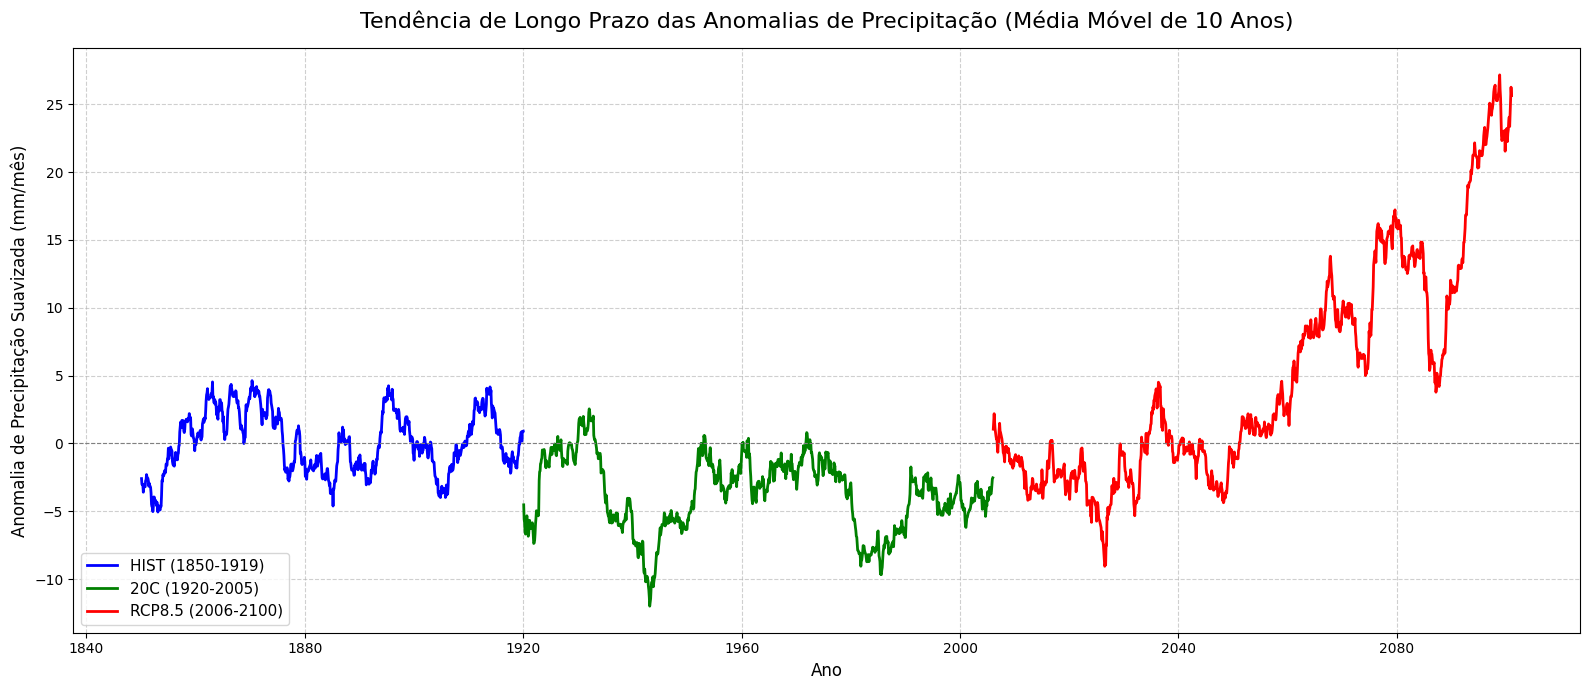

In [3]:
# ==============================================================================
# PASSO 2.1: CÁLCULO DA CLIMATOLOGIA DE REFERÊNCIA (BASELINE = HIST)
# ==============================================================================

# Agrupamos a série HIST por mês do ano (1 a 12) e calculamos a média de cada mês.
# Isso gera o perfil sazonal esperado para a bacia (Climatologia de Referência).
climatologia_hist = precip_mensal_hist.groupby(precip_mensal_hist.index.month).mean()

# ==============================================================================
# PASSO 2.2: CÁLCULO DAS SÉRIES DE ANOMALIAS
# ==============================================================================

# Para cada registro, subtraímos a média histórica correspondente àquele mês do ano.
# O método .index.month serve para mapear qual mês (1-12) deve ser subtraído.
anomalia_hist  = precip_mensal_hist - precip_mensal_hist.index.month.map(climatologia_hist)
anomalia_20c   = precip_mensal_20c - precip_mensal_20c.index.month.map(climatologia_hist)
anomalia_rcp85 = precip_mensal_rcp85 - precip_mensal_rcp85.index.month.map(climatologia_hist)

# ==============================================================================
# PASSO 2.3: FILTRO DE BAIXA FREQUÊNCIA (MÉDIA MÓVEL DE 13 MESES)
# ==============================================================================

# Aplicamos a média móvel de 13 meses com 'center=True' para centralizar a janela temporal.
# Isso suaviza os ruídos transientes intermensais e destaca as tendências de longo prazo.
anomalia_hist_suave  = anomalia_hist.rolling(window=13, center=True).mean()
anomalia_20c_suave   = anomalia_20c.rolling(window=13, center=True).mean()
anomalia_rcp85_suave = anomalia_rcp85.rolling(window=13, center=True).mean()

# ==============================================================================
# VERIFICAÇÃO DOS RESULTADOS
# ==============================================================================
print("--- ETAPA 2 CONCLUÍDA COM SUCESSO ---")
print("Perfil da Climatologia HIST (Média Mensal Esperada em mm):")
for mes, valor in climatologia_hist.items():
    print(f" Mês {mes:02d}: {valor:.2f} mm")

print("\nVerificação de valores nulos gerados pelas bordas da Média Móvel (janela centrada):")
print(f" NaNs no HIST Suave:  {anomalia_hist_suave.isna().sum()} meses (esperado: 12)")
print(f" NaNs no 20C Suave:   {anomalia_20c_suave.isna().sum()} meses (esperado: 12)")
print(f" NaNs no RCP8.5 Suave: {anomalia_rcp85_suave.isna().sum()} meses (esperado: 12)")

# ==============================================================================
# PASSO 2.4: FILTRO DE BAIXA FREQUÊNCIA (MÉDIA MÓVEL DE 10 ANOS / 120 MESES)
# Para plotagem da tendência principal
# ==============================================================================

# Aplicamos a média móvel de 120 meses (10 anos) para destacar tendências de longo prazo.
# min_periods=60 garante que a média só seja calculada com pelo menos 5 anos de dados.
anomalia_hist_suave_10anos  = anomalia_hist.rolling(window=120, center=True, min_periods=60).mean()
anomalia_20c_suave_10anos   = anomalia_20c.rolling(window=120, center=True, min_periods=60).mean()
anomalia_rcp85_suave_10anos = anomalia_rcp85.rolling(window=120, center=True, min_periods=60).mean()

# ==============================================================================
# GERAÇÃO DO GRÁFICO DA MÉDIA MÓVEL DE 10 ANOS
# ==============================================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

plt.plot(anomalia_hist_suave_10anos.index, anomalia_hist_suave_10anos, label='HIST (1850-1919)', color='blue', lw=2)
plt.plot(anomalia_20c_suave_10anos.index, anomalia_20c_suave_10anos, label='20C (1920-2005)', color='green', lw=2)
plt.plot(anomalia_rcp85_suave_10anos.index, anomalia_rcp85_suave_10anos, label='RCP8.5 (2006-2100)', color='red', lw=2)

plt.title('Tendência de Longo Prazo das Anomalias de Precipitação (Média Móvel de 10 Anos)', fontsize=16, pad=15)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Anomalia de Precipitação Suavizada (mm/mês)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8) # Linha de referência no zero
plt.legend(fontsize=11, loc='lower left')
plt.tight_layout()
plt.show()

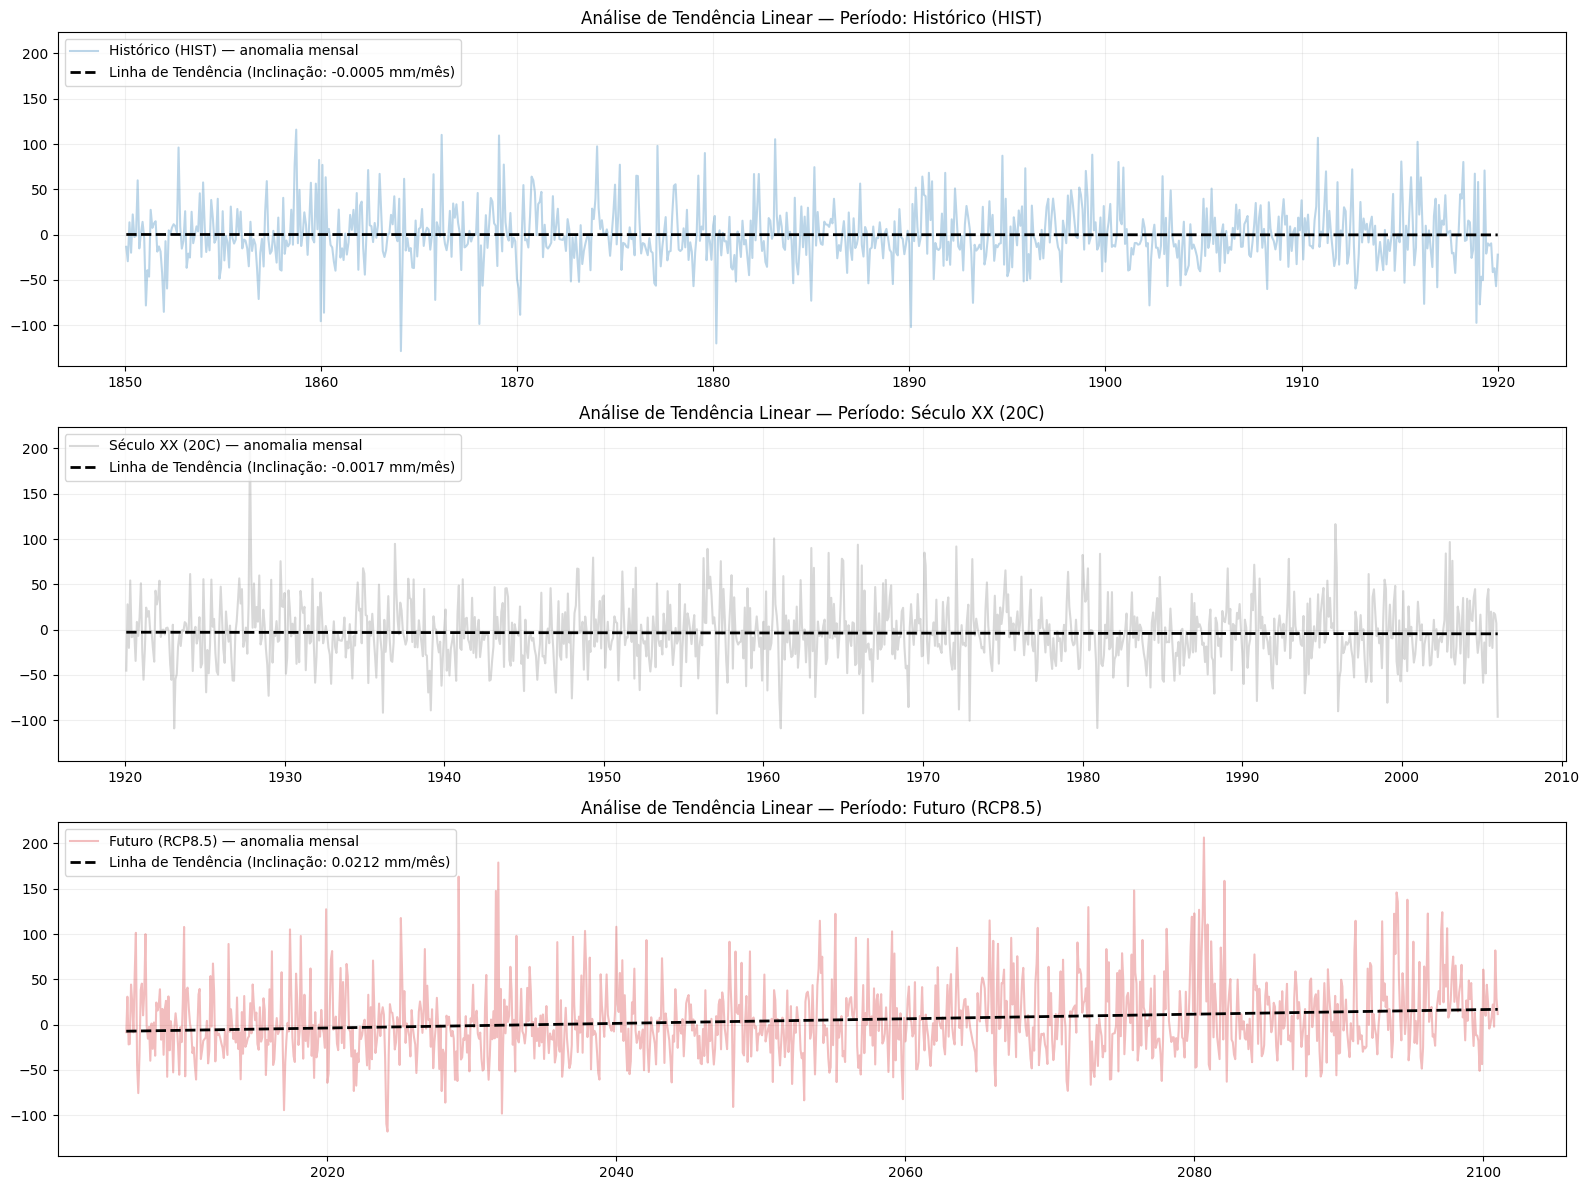

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(16, 12), sharey=True)

def plotar_reta_tendencia(df, ax, nome_serie, cor_real):
    y = df.values
    x = np.arange(len(y))

    # Regressão Linear Simples
    coef = np.polyfit(x, y, 1)
    reta = np.polyval(coef, x)

    ax.plot(df.index, y, color=cor_real, alpha=0.3, label=f'{nome_serie} — anomalia mensal')
    ax.plot(df.index, reta, color='black', linestyle='--', lw=2,
            label=f'Linha de Tendência (Inclinação: {coef[0]:.4f} mm/mês)')
    ax.set_title(f'Análise de Tendência Linear — Período: {nome_serie}', fontsize=12)
    ax.legend(loc='upper left')
    ax.grid(alpha=0.2)

    return coef[0]

taxa_hist = plotar_reta_tendencia(anomalia_hist, ax1, 'Histórico (HIST)', '#1f77b4')
taxa_20c  = plotar_reta_tendencia(anomalia_20c,  ax2, 'Século XX (20C)', '#7f7f7f')
taxa_rcp  = plotar_reta_tendencia(anomalia_rcp85, ax3, 'Futuro (RCP8.5)', '#d62728')

plt.tight_layout()
plt.show()

# Etapa 3: Diagnóstico de Estacionaridade (Testes ADF e KPSS)

Esta etapa consiste na aplicação combinada de testes estatísticos de hipótese sobre as séries de anomalias de precipitação. O objetivo é mapear se as propriedades estatísticas (média e variância) do regime pluviométrico da UGRH Paranapanema alteram-se significativamente entre os períodos pré-industrial (HIST), contemporâneo (20C) e de projeção futura (RCP8.5).

O cruzamento dos testes ADF e KPSS permite classificar a série sob quatro diagnósticos:
1. **Estacionária:** ADF rejeita H0 (p < 0,05) e KPSS não rejeita H0 (p > 0,05).
2. **Não estacionária (raiz unitária):** ADF não rejeita H0 e KPSS rejeita H0.
3. **Ambos rejeitam H0:** sem raiz unitária, mas a média não é constante — indício de tendência determinística ou quebra estrutural.
4. **Inconclusivo:** nenhum dos dois testes rejeita H0.

Este diagnóstico serve de base para discutir se a hipótese de estacionariedade, usada no dimensionamento de infraestruturas e outorgas descritas no PIRH, se mantém nas simulações.

In [5]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

# ==============================================================================
# PASSO 3.1: DEFINIÇÃO DA FUNÇÃO EXECUTORA DOS TESTES COMBINADOS
# ==============================================================================
def realizar_diagnostico_estacionaridade(serie, nome_cenario):
    """
    Aplica os testes ADF e KPSS em uma série de anomalias (removendo NaNs),
    retornando um dicionário estruturado com os resultados.
    """
    # Remove eventuais valores nulos antes dos cálculos estatísticos
    serie_limpa = serie.dropna()

    # 1. Execução do Teste ADF (Augmented Dickey-Fuller)
    # H0: A série possui raiz unitária (Não-Estacionária)
    # H1: A série é Estacionária
    resultado_adf = adfuller(serie_limpa, autolag='AIC')
    estatistica_adf = resultado_adf[0]
    p_valor_adf = resultado_adf[1]

    # 2. Execução do Teste KPSS (Kwiatkowski-Phillips-Schmidt-Shin)
    # H0: A série é Estacionária
    # H1: A série não é Estacionária
    # O argumento regression='c' testa a estacionaridade em torno de uma constante
    resultado_kpss = kpss(serie_limpa, regression='c', nlags='auto')
    estatistica_kpss = resultado_kpss[0]
    p_valor_kpss = resultado_kpss[1]

    # 3. Classificação automatizada com base nos p-valores (Alfa = 5%)
    alfa = 0.05
    adf_estacionario = (p_valor_adf < alfa)
    kpss_estacionario = (p_valor_kpss > alfa)

    if adf_estacionario and kpss_estacionario:
        diagnostico = "Estacionária"
    elif (not adf_estacionario) and (not kpss_estacionario):
        diagnostico = "Não estacionária (raiz unitária)"
    elif adf_estacionario and (not kpss_estacionario):
        diagnostico = "Ambos rejeitam H0 (indício de tendência)"
    else:
        diagnostico = "Inconclusivo"

    # Retorna as métricas organizadas
    return {
        "Cenário": nome_cenario,
        "ADF Estatística": estatistica_adf,
        "ADF p-valor": p_valor_adf,
        "KPSS Estatística": estatistica_kpss,
        "KPSS p-valor": p_valor_kpss,
        "Diagnóstico Final": diagnostico
    }

# ==============================================================================
# PASSO 3.2: PROCESSAMENTO DOS TRÊS HORIZONTES CLIMÁTICOS
# ==============================================================================
# Aplicamos as anomalias brutas geradas no Passo 2.2 para evitar distorções de lags
res_hist  = realizar_diagnostico_estacionaridade(anomalia_hist, "HIST (1850-1919)")
res_20c   = realizar_diagnostico_estacionaridade(anomalia_20c, "20C (1920-2005)")
res_rcp85 = realizar_diagnostico_estacionaridade(anomalia_rcp85, "RCP8.5 (2006-2100)")

# ==============================================================================
# PASSO 3.3: CONSTRUÇÃO DA TABELA RESUMO FINAL
# ==============================================================================
tabela_estacionaridade = pd.DataFrame([res_hist, res_20c, res_rcp85])

# Configura o cenário como índice para melhorar o visual e a legibilidade da tabela
tabela_estacionaridade.set_index("Cenário", inplace=True)

# Exibe a tabela formatada com 4 casas decimais para os valores numéricos
print("--- ETAPA 3: DIAGNÓSTICO DE ESTACIONARIDADE CONCLUÍDO ---")
display(tabela_estacionaridade.round(4))

/tmp/ipykernel_3668/2262018333.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie_limpa, autolag='AIC')
/tmp/ipykernel_3668/2262018333.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  resultado_kpss = kpss(serie_limpa, regression='c', nlags='auto')
/tmp/ipykernel_3668/2262018333.py:26: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will sw

--- ETAPA 3: DIAGNÓSTICO DE ESTACIONARIDADE CONCLUÍDO ---


/tmp/ipykernel_3668/2262018333.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie_limpa, autolag='AIC')
/tmp/ipykernel_3668/2262018333.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  resultado_kpss = kpss(serie_limpa, regression='c', nlags='auto')
/tmp/ipykernel_3668/2262018333.py:26: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will sw

,ADF Estatística,ADF p-valor,KPSS Estatística,KPSS p-valor,Diagnóstico Final
Cenário,,,,,
HIST (1850-1919),-18.7252,0.0,0.0357,0.10,Estacionária
20C (1920-2005),-28.5987,0.0,0.0609,0.10,Estacionária
RCP8.5 (2006-2100),-7.6124,0.0,2.3152,0.01,Ambos rejeitam H0 (indício de tendência)


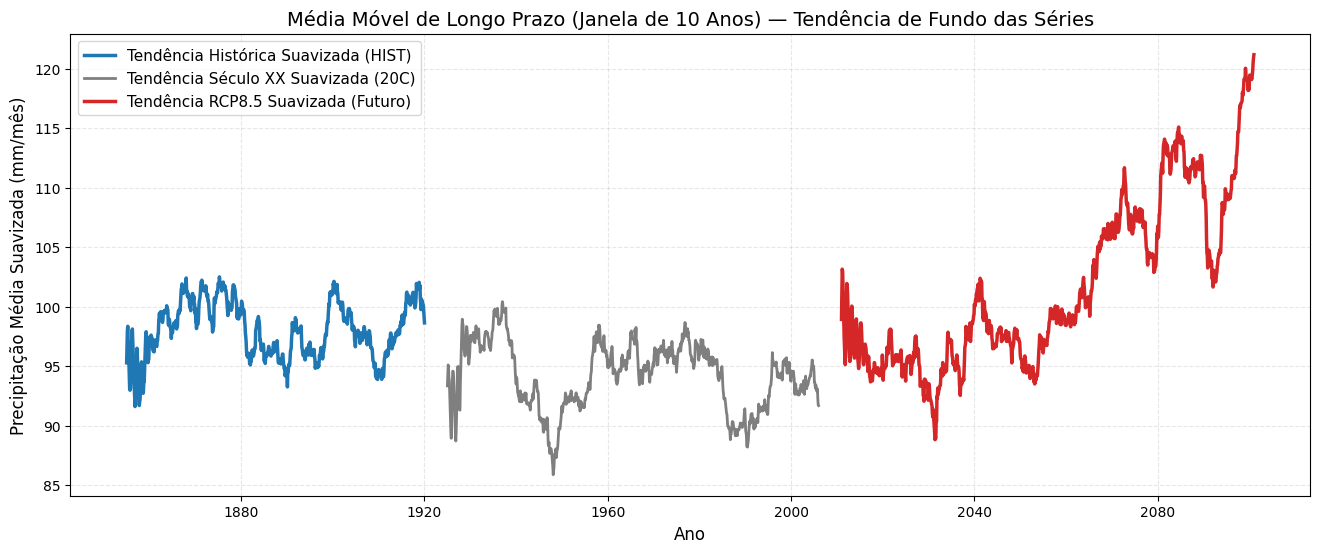

In [6]:
hist_suave = precip_mensal_hist.rolling(window=120, min_periods=60).mean()
c20_suave = precip_mensal_20c.rolling(window=120, min_periods=60).mean()
rcp_suave = precip_mensal_rcp85.rolling(window=120, min_periods=60).mean()

plt.figure(figsize=(16, 6))

plt.plot(hist_suave.index, hist_suave, label='Tendência Histórica Suavizada (HIST)', color='#1f77b4', lw=2.5)
plt.plot(c20_suave.index, c20_suave, label='Tendência Século XX Suavizada (20C)', color='#7f7f7f', lw=2)
plt.plot(rcp_suave.index, rcp_suave, label='Tendência RCP8.5 Suavizada (Futuro)', color='#d62728', lw=2.5)

plt.title('Média Móvel de Longo Prazo (Janela de 10 Anos) — Tendência de Fundo das Séries', fontsize=14)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Precipitação Média Suavizada (mm/mês)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3, linestyle='--')

plt.show()

# Etapa 4: Análise de Volatilidade (Variância Móvel) e Memória Temporal (ACF/PACF)

O objetivo desta etapa é investigar a evolução temporal da variabilidade estatística e a persistência dos sinais pluviais na UGRH Paranapanema.

Para isso, o fluxo de trabalho compreende:
1. O cálculo da **Variância Móvel (Rolling Variance)** utilizando uma janela decenal móvel de 120 meses sobre as séries de anomalias de precipitação, permitindo identificar o aumento ou redução da volatilidade hídrica ao longo dos horizontes temporais.
2. A geração dos gráficos da **Função de Autocorrelação (ACF)** e **Função de Autocorrelação Parcial (PACF)** para quantificar a memória temporal e a estrutura de dependência estocástica dos três cenários estudados.

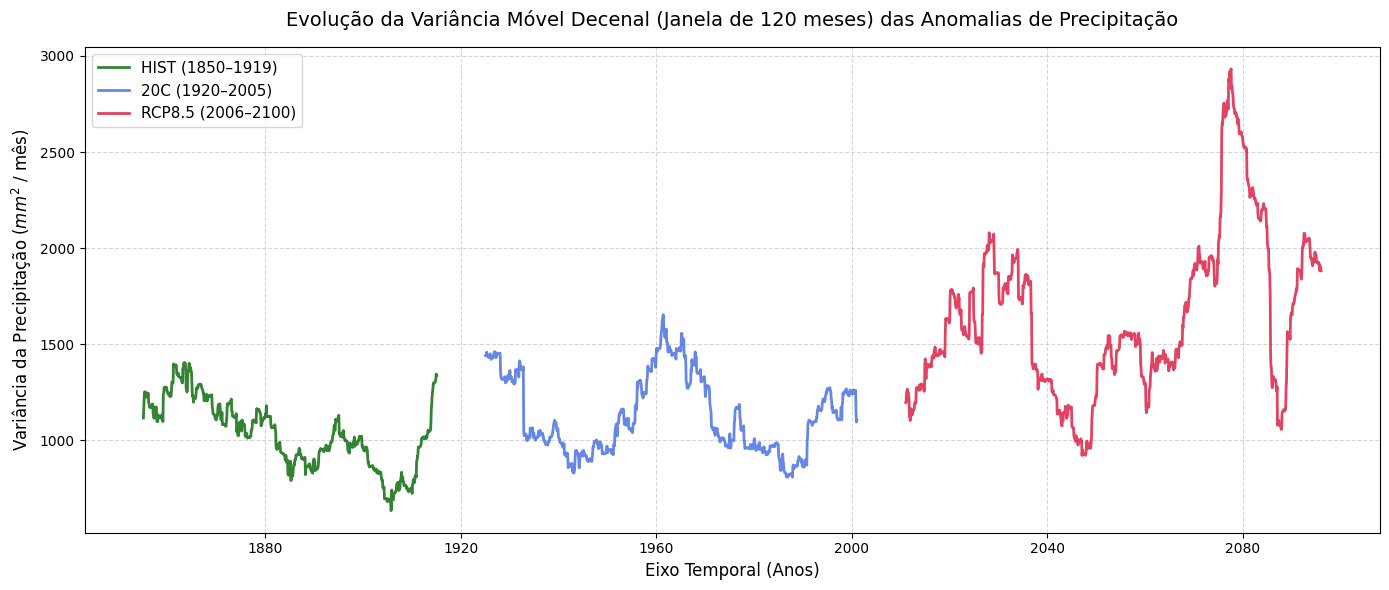

In [7]:
import matplotlib.pyplot as plt

# ==============================================================================
# PASSO 4.1: CÁLCULO DA VARIÂNCIA MÓVEL DECENAL (JANELA DE 120 MESES)
# ==============================================================================
# Calculamos a volatilidade diretamente sobre as anomalias mensais brutas
var_movel_hist  = anomalia_hist.rolling(window=120, center=True).var()
var_movel_20c   = anomalia_20c.rolling(window=120, center=True).var()
var_movel_rcp85 = anomalia_rcp85.rolling(window=120, center=True).var()

# ==============================================================================
# PLOTAGEM DO GRÁFICO DE VOLATILIDADE COMPARATIVO
# ==============================================================================
plt.figure(figsize=(14, 6))

plt.plot(var_movel_hist.index, var_movel_hist, label='HIST (1850–1919)', color='darkgreen', alpha=0.8, linewidth=2)
plt.plot(var_movel_20c.index, var_movel_20c, label='20C (1920–2005)', color='royalblue', alpha=0.8, linewidth=2)
plt.plot(var_movel_rcp85.index, var_movel_rcp85, label='RCP8.5 (2006–2100)', color='crimson', alpha=0.8, linewidth=2)

# Configurações estéticas e legendas
plt.title('Evolução da Variância Móvel Decenal (Janela de 120 meses) das Anomalias de Precipitação', fontsize=14, pad=15)
plt.xlabel('Eixo Temporal (Anos)', fontsize=12)
plt.ylabel('Variância da Precipitação ($mm^2$ / mês)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()

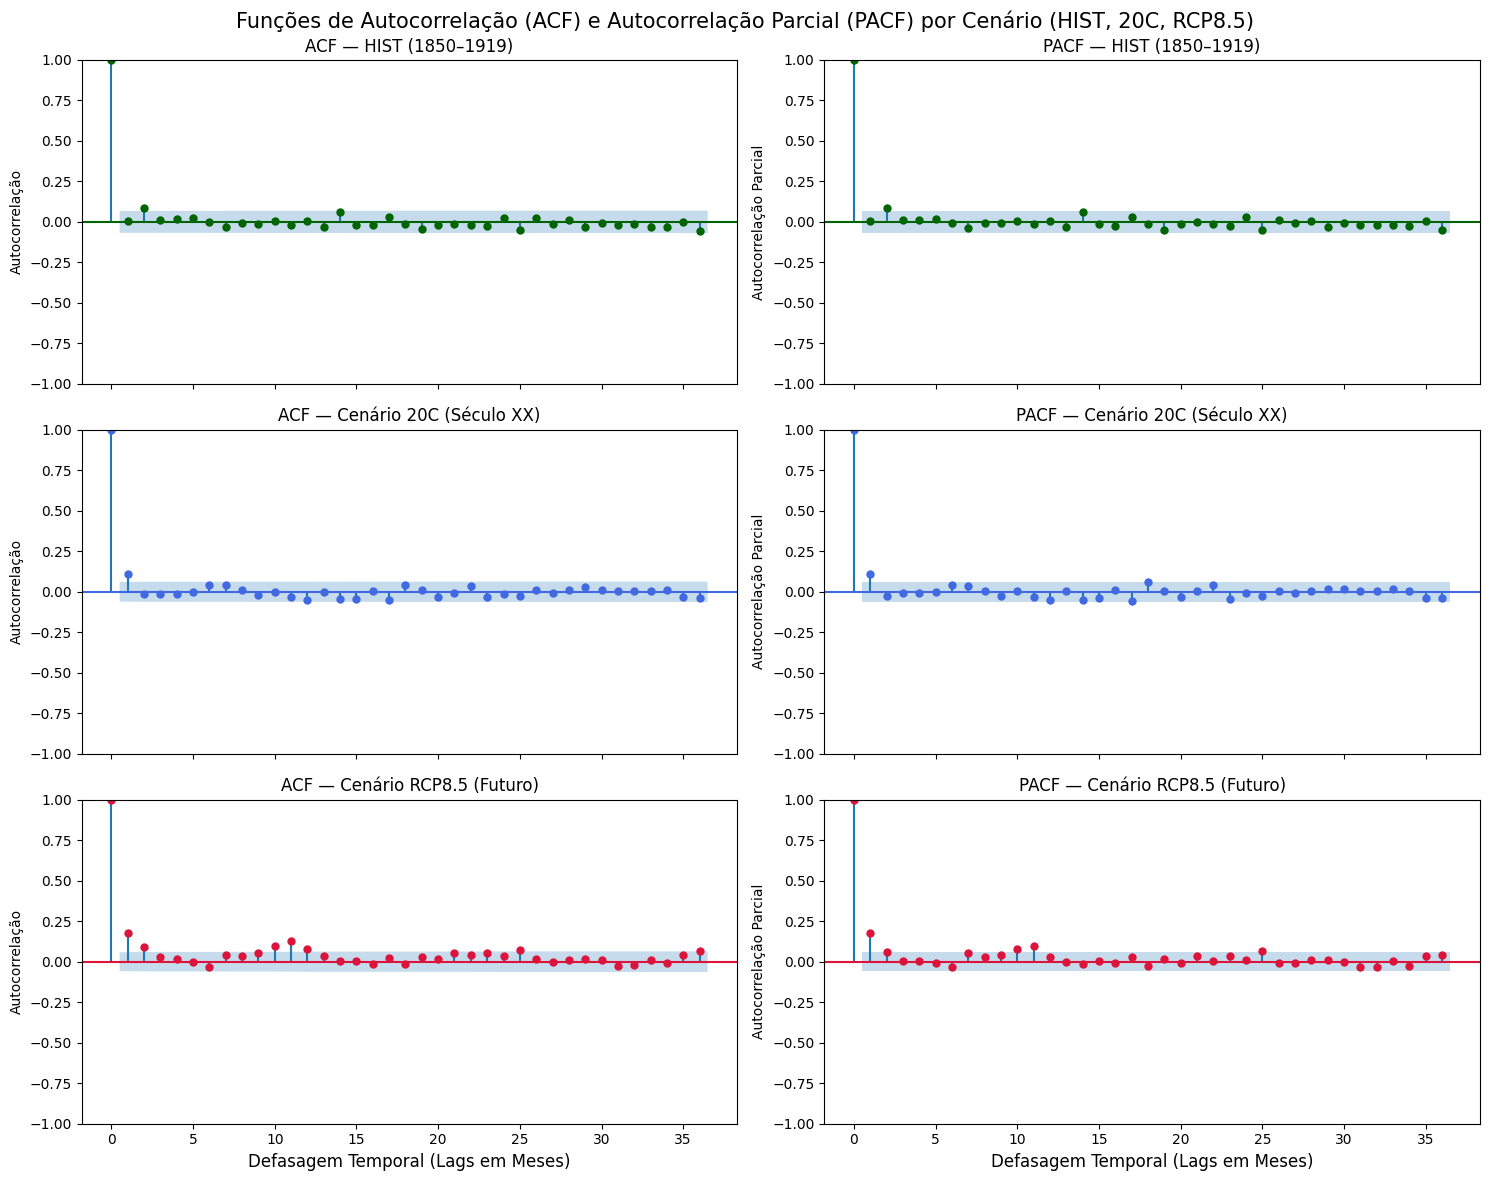

In [8]:
# ==============================================================================
# PASSO 4.2: GERAÇÃO DA MATRIZ DE SUBPLOTS PARA MEMÓRIA TEMPORAL (ACF / PACF)
# ==============================================================================

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Criamos uma matriz de 3 linhas (uma para cada cenário) e 2 colunas (ACF e PACF)
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex='col')

# Cenário HIST (Linha 0)
plot_acf(anomalia_hist.dropna(), lags=36, ax=axes[0, 0], color='darkgreen', title='ACF — HIST (1850–1919)')
plot_pacf(anomalia_hist.dropna(), lags=36, ax=axes[0, 1], color='darkgreen', title='PACF — HIST (1850–1919)')

# Cenário 20C (Linha 1)
plot_acf(anomalia_20c.dropna(), lags=36, ax=axes[1, 0], color='royalblue', title='ACF — Cenário 20C (Século XX)')
plot_pacf(anomalia_20c.dropna(), lags=36, ax=axes[1, 1], color='royalblue', title='PACF — Cenário 20C (Século XX)')

# Cenário RCP8.5 (Linha 2)
plot_acf(anomalia_rcp85.dropna(), lags=36, ax=axes[2, 0], color='crimson', title='ACF — Cenário RCP8.5 (Futuro)')
plot_pacf(anomalia_rcp85.dropna(), lags=36, ax=axes[2, 1], color='crimson', title='PACF — Cenário RCP8.5 (Futuro)')

# Ajustes de eixos e rótulos
for i in range(3):
    axes[i, 0].set_ylabel('Autocorrelação', fontsize=10)
    axes[i, 1].set_ylabel('Autocorrelação Parcial', fontsize=10)
axes[2, 0].set_xlabel('Defasagem Temporal (Lags em Meses)', fontsize=12)
axes[2, 1].set_xlabel('Defasagem Temporal (Lags em Meses)', fontsize=12)

plt.suptitle('Funções de Autocorrelação (ACF) e Autocorrelação Parcial (PACF) por Cenário (HIST, 20C, RCP8.5)', fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

# Etapa 5: Análise de Distribuição e Frequência de Extremos (Boxplots e Histogramas)

Esta etapa final do processamento computacional visa consolidar as alterações na estrutura distributiva das anomalias de precipitação da UGRH Paranapanema.

Para isso, o código executa:
1. A construção de **Boxplots (Diagramas de Caixa)** comparativos lado a lado para os três cenários (HIST, 20C e RCP8.5), evidenciando visualmente as alterações na mediana, nos quartis e o comportamento dos valores discrepantes (*outliers*).
2. A plotagem de **Histogramas de Frequência** com curvas de densidade sobrepostas, permitindo avaliar visualmente o achatamento da distribuição (curtose) e o deslocamento das caudas de eventos extremos nos diferentes horizontes climáticos.

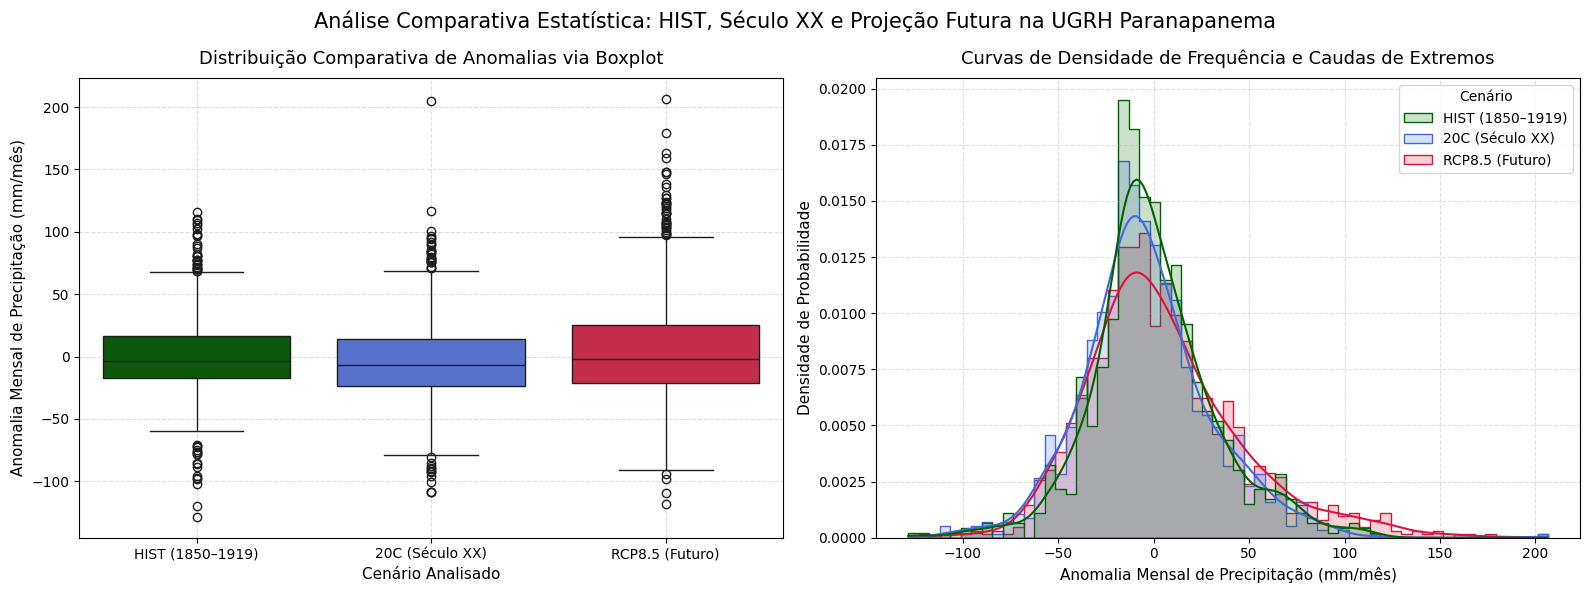

--- ANÁLISE CONCLUÍDA ---


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Concatenamos os três cenários para a comparação das distribuições
dados_hist = pd.DataFrame({'Anomalia': anomalia_hist.dropna(), 'Cenário': 'HIST (1850–1919)'})
dados_20c = pd.DataFrame({'Anomalia': anomalia_20c.dropna(), 'Cenário': '20C (Século XX)'})
dados_rcp = pd.DataFrame({'Anomalia': anomalia_rcp85.dropna(), 'Cenário': 'RCP8.5 (Futuro)'})
df_distribuicao_filtrada = pd.concat([dados_hist, dados_20c, dados_rcp])

# Geração dos subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICO 1: BOXPLOT COMPARATIVO ---
sns.boxplot(
    data=df_distribuicao_filtrada,
    x='Cenário',
    y='Anomalia',
    ax=axes[0],
    palette=['darkgreen', 'royalblue', 'crimson'],
    hue='Cenário',
    legend=False
)
axes[0].set_title('Distribuição Comparativa de Anomalias via Boxplot', fontsize=13, pad=10)
axes[0].set_xlabel('Cenário Analisado', fontsize=11)
axes[0].set_ylabel('Anomalia Mensal de Precipitação (mm/mês)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.4)

# --- GRÁFICO 2: HISTOGRAMA DE DENSIDADE (KDE) ---
sns.histplot(
    data=df_distribuicao_filtrada,
    x='Anomalia',
    hue='Cenário',
    kde=True,
    stat='density',
    element='step',
    common_norm=False,
    ax=axes[1],
    palette=['darkgreen', 'royalblue', 'crimson'],
    alpha=0.2
)
axes[1].set_title('Curvas de Densidade de Frequência e Caudas de Extremos', fontsize=13, pad=10)
axes[1].set_xlabel('Anomalia Mensal de Precipitação (mm/mês)', fontsize=11)
axes[1].set_ylabel('Densidade de Probabilidade', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Análise Comparativa Estatística: HIST, Século XX e Projeção Futura na UGRH Paranapanema', fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

print("--- ANÁLISE CONCLUÍDA ---")

In [10]:
# Tabela comparativa final
tabela_final_completa = pd.DataFrame(index=['Média Mensal (mm)', 'Desvio-Padrão (mm)', 'Mínimo Mensal (mm)', 'Máximo Mensal (mm)', 'Tendência Linear da Anomalia (mm/mês por mês)'])

# Estatísticas descritivas calculadas sobre a precipitação acumulada absoluta, e a tendência sobre a anomalia
tabela_final_completa['HISTÓRICO'] = [precip_mensal_hist.mean(), precip_mensal_hist.std(), precip_mensal_hist.min(), precip_mensal_hist.max(), taxa_hist]
tabela_final_completa['20C']       = [precip_mensal_20c.mean(),  precip_mensal_20c.std(),  precip_mensal_20c.min(),  precip_mensal_20c.max(),  taxa_20c]
tabela_final_completa['RCP8.5']    = [precip_mensal_rcp85.mean(), precip_mensal_rcp85.std(), precip_mensal_rcp85.min(), precip_mensal_rcp85.max(), taxa_rcp]

print("📊 RESUMO ESTATÍSTICO — UGRH PARANAPANEMA")
display(tabela_final_completa.round(3))

📊 RESUMO ESTATÍSTICO — UGRH PARANAPANEMA


,HISTÓRICO,20C,RCP8.5
Média Mensal (mm),97.887,94.207,102.753
Desvio-Padrão (mm),76.309,75.976,84.469
Mínimo Mensal (mm),0.000,0.000,0.000
Máximo Mensal (mm),324.941,307.303,378.848
Tendência Linear da Anomalia (mm/mês por mês),-0.001,-0.002,0.021
